Intro

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm

rawdata="student-mat.csv"

df = pd.read_csv(rawdata, sep=";")
finalGrades=df["G3"].values

In [3]:
# Calculate summary stats
mean = np.mean(finalGrades)
median = np.median(finalGrades)
standardDeviation = np.std(finalGrades)

print(f"Summary stastics:\n\tMean: {mean}\n\tMedian: {median}\n\tStandard Deviation: {standardDeviation}")

Summary stastics:
	Mean: 10.415189873417722
	Median: 11.0
	Standard Deviation: 4.57563964146053


## Observations
- The grade distribution appears approximately normal, except for a high concentration of failing grades.

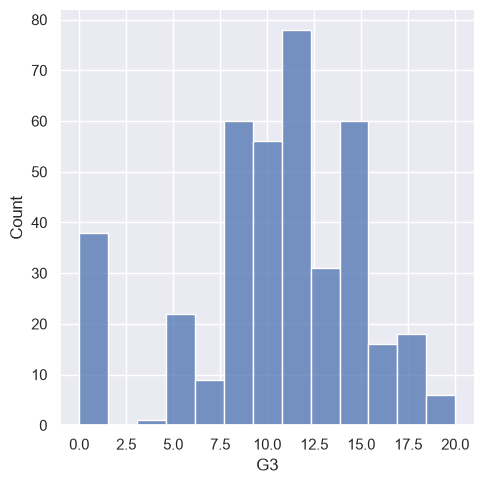

In [4]:
sns.set_theme()
histogram = sns.displot(data=df, x="G3")

In [5]:
correlations = df.corr(numeric_only=True)["G3"]
print(correlations.sort_values(ascending=False))

G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


<Axes: xlabel='failures', ylabel='G3'>

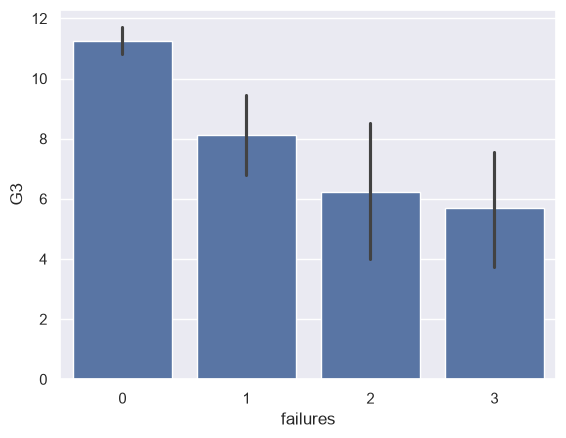

In [6]:
sns.barplot(data=df, x = "failures", y = "G3")

<Axes: xlabel='higher', ylabel='G3'>

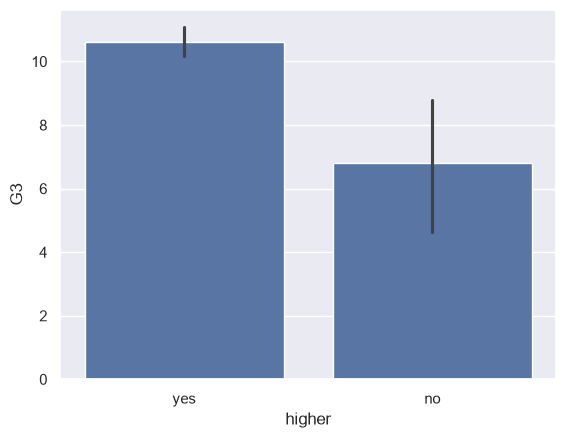

In [7]:
sns.barplot(data=df, x = "higher", y = "G3")

<Axes: xlabel='G1', ylabel='G3'>

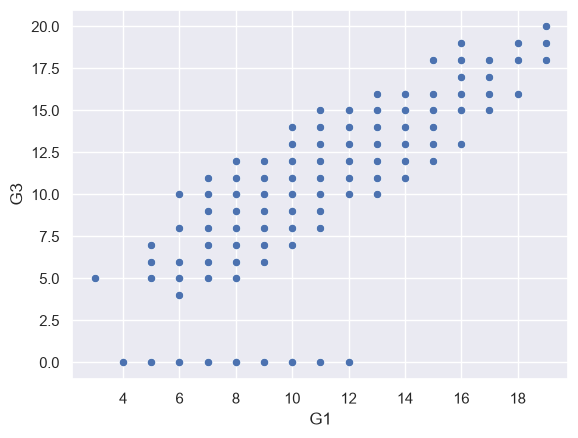

In [25]:
sns.scatterplot(data=df, x = "G1", y = "G3")

In [26]:
for attribute in df.columns:
    if attribute == "G3" or attribute == "G1" or attribute == "G2":
        continue
    print(df.groupby(attribute)["G3"].mean().to_string() + "\n")

school
GP    10.489971
MS     9.847826

sex
F     9.966346
M    10.914439

age
15    11.256098
16    11.028846
17    10.275510
18     9.548780
19     8.208333
20    14.000000
21     7.000000
22     8.000000

address
R     9.511364
U    10.674267

famsize
GT3    10.177936
LE3    11.000000

Pstatus
A    11.195122
T    10.324859

Medu
0    13.000000
1     8.677966
2     9.728155
3    10.303030
4    11.763359

Fedu
0    13.000000
1     9.158537
2    10.260870
3    10.660000
4    11.364583

Mjob
at_home      9.152542
health      12.147059
other        9.822695
services    11.019417
teacher     11.051724

Fjob
at_home     10.150000
health      11.611111
other       10.193548
services    10.297297
teacher     11.965517

reason
course         9.820690
home          10.256881
other         11.166667
reputation    11.142857

guardian
father    10.688889
mother    10.483516
other      9.062500

traveltime
1    10.782101
2     9.906542
3     9.260870
4     8.750000

studytime
1    10.047619
2    1

- Using only G1 and G2 to predict G3 with linear regression:

In [31]:
X_train, X_test, y_train, y_test = train_test_split(df[["G1", "G2"]], df["G3"], test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

print("R^2:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

R^2: 0.7945936216805897
MSE: 4.2118674966017595


References
- https://www.geeksforgeeks.org/machine-learning/best-python-libraries-for-machine-learning/
- https://realpython.com/python-seaborn/
- https://seaborn.pydata.org/tutorial/distributions.html
- https://stackoverflow.com/a/34796529